### **DATA ANALYSIS PYTHON PROJECT - BLINKIT ANALYSIS**

In [ ]:
! pip install matplotlib seaborn

#### **Import Libraries**

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

#### **import Rawdata**

In [6]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\drive-download-20261026T064950Z-1-001\blinkit_data.csv")

In [7]:
df.head(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,low fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0
7,Low Fat,NCD30,Household,2015,OUT045,Tier 2,Small,Supermarket Type1,0.026904,19.70,96.0726,5.0
8,Low Fat,FDW20,Fruits and Vegetables,2000,OUT013,Tier 3,High,Supermarket Type1,0.024129,20.75,124.1730,5.0
9,Low Fat,FDX25,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.101562,NaN,181.9292,5.0


#### **Fileds**

In [8]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

In [9]:
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

In [11]:
df.shape

(8523, 12)

In [12]:
df.dropna(inplace=True)

In [13]:
df.shape

(7060, 12)

In [14]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

#### **Data Cleaning**

In [15]:
df['Item Fat Content'].unique()

<StringArray>
['Regular', 'Low Fat', 'low fat', 'LF', 'reg']
Length: 5, dtype: str

In [19]:
df['Item Fat Content'] = df['Item Fat Content'].replace({'LF':'Low Fat',
                                'low fat':'Low Fat','reg':'Regular'})

In [20]:
df['Item Fat Content'].unique()

<StringArray>
['Regular', 'Low Fat']
Length: 2, dtype: str

#### **KPI'S**

In [21]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

In [23]:
Total_Sales = df['Sales'].sum()
Avg_Sales = df['Sales'].mean()
No_Items = df['Item Type'].count()
Avg_Rating = df['Rating'].mean()

print("Total Sales: ", Total_Sales)
print("Average Sales: ", Avg_Sales)
print("Number of Items: ", No_Items)
print("Average Rating: ", Avg_Rating)

Total Sales:  997159.2238
Average Sales:  141.24068325779038
Number of Items:  7060
Average Rating:  3.965382436260623


#### **Exploratory Data Analysis**

Total Sales by Fat Content:   Item Fat Content        Sales
0          Low Fat  644516.7320
1          Regular  352642.4918


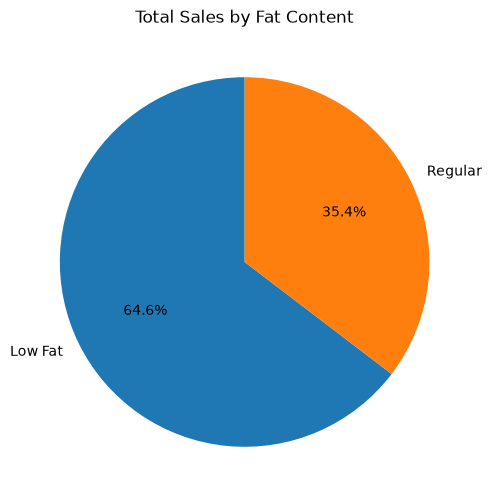

In [28]:
Total_Sales_by_Fat_Content = df.groupby('Item Fat Content')['Sales'].sum().reset_index()

print("Total Sales by Fat Content:", Total_Sales_by_Fat_Content)

# Create Pie Chart
plt.figure(figsize=(6, 6))

plt.pie(
    Total_Sales_by_Fat_Content['Sales'],
    labels=Total_Sales_by_Fat_Content['Item Fat Content'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Total Sales by Fat Content')
plt.show()

In [29]:
df['Item Type'].value_counts()

Item Type
Fruits and Vegetables    1019
Snack Foods               988
Household                 759
Frozen Foods              718
Dairy                     566
Canned                    539
Baking Goods              536
Health and Hygiene        430
Soft Drinks               374
Meat                      337
Breads                    204
Hard Drinks               183
Others                    137
Starchy Foods             130
Breakfast                  89
Seafood                    51
Name: count, dtype: int64

                Item Type        Sales
0            Baking Goods   67588.1130
1                  Breads   28663.1848
2               Breakfast   12696.1874
3                  Canned   75052.9980
4                   Dairy   84526.4948
5            Frozen Foods   99961.8818
6   Fruits and Vegetables  147188.9632
7             Hard Drinks   25261.6174
8      Health and Hygiene   56383.8020
9               Household  113210.1420
10                   Meat   47159.9010
11                 Others   18624.5970
12                Seafood    7397.5644
13            Snack Foods  144949.1280
14            Soft Drinks   49294.6718
15          Starchy Foods   19199.9772


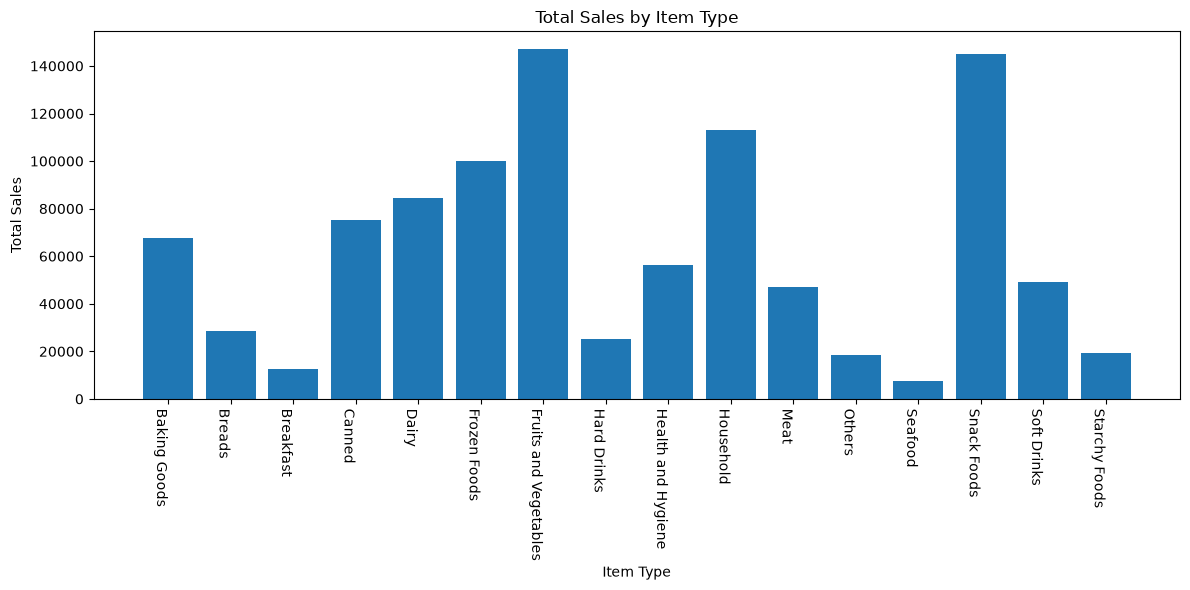

In [32]:
# Calculate total sales by Item Type
Total_Sales_By_Item = df.groupby('Item Type')['Sales'].sum().reset_index()

print(Total_Sales_By_Item)

# Create Bar Chart
plt.figure(figsize=(12, 6))

plt.bar(
    Total_Sales_By_Item['Item Type'],
    Total_Sales_By_Item['Sales']
)

plt.title('Total Sales by Item Type')
plt.xlabel('Item Type')
plt.ylabel('Total Sales')

plt.xticks(rotation=-90, ha='right')
plt.tight_layout()
plt.show()

  Item Fat Content        Sales
0          Low Fat  644516.7320
1          Regular  352642.4918


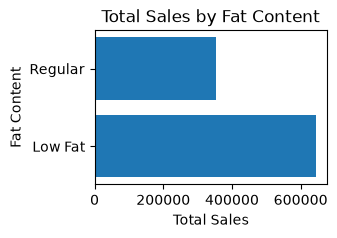

In [39]:
Fat_Content_by_Sales = df.groupby('Item Fat Content')['Sales'].sum().reset_index()

print(Fat_Content_by_Sales)

## Create hbar chart
plt.figure(figsize=(3,2))
plt.barh(
    Fat_Content_by_Sales['Item Fat Content'],
    Fat_Content_by_Sales['Sales']
)
plt.title('Total Sales by Fat Content')
plt.xlabel('Total Sales')
plt.ylabel('Fat Content')
plt.show()

   Outlet Establishment Year        Sales
0                       2000  131809.0156
1                       2010  132113.3698
2                       2011   78131.5646
3                       2012  130476.8598
4                       2015  130942.7782
5                       2017  133103.9070
6                       2020  129103.9564
7                       2022  131477.7724


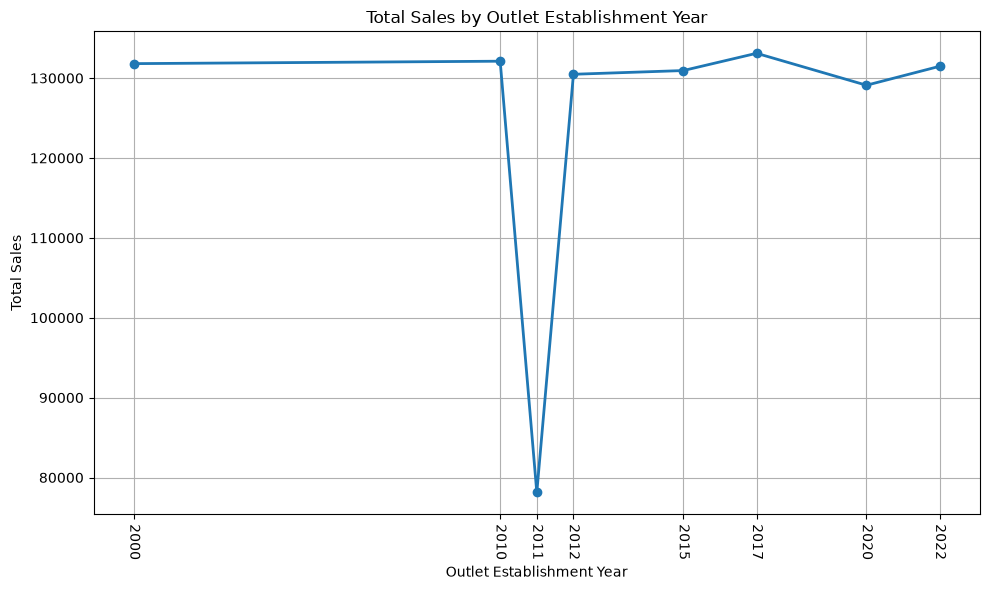

In [42]:
Total_Sales_by_Outlet_Establishment = df.groupby('Outlet Establishment Year')['Sales'].sum().reset_index()

print(Total_Sales_by_Outlet_Establishment)

# Create visualization
plt.figure(figsize=(10, 6))

plt.plot(
    Total_Sales_by_Outlet_Establishment['Outlet Establishment Year'],
    Total_Sales_by_Outlet_Establishment['Sales'],
    marker='o',
    linewidth=2
)

plt.title('Total Sales by Outlet Establishment Year')
plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')
plt.xticks(
    Total_Sales_by_Outlet_Establishment['Outlet Establishment Year'],
    rotation=-90
)
plt.grid(True)
plt.tight_layout()
plt.show()

  Outlet Size        Sales
0        High  248991.5840
1      Medium  377181.0538
2       Small  370986.5860


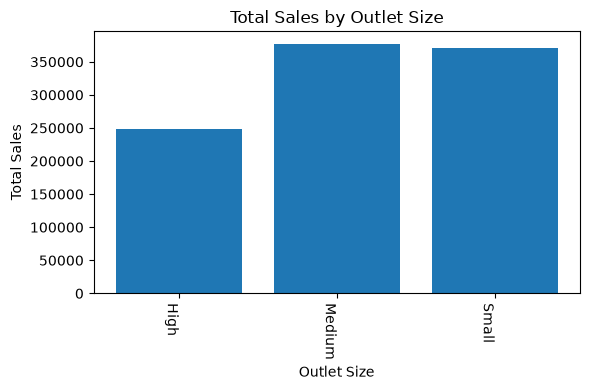

In [45]:
Sales_by_Outlet_Size = df.groupby('Outlet Size')['Sales'].sum().reset_index()

print(Sales_by_Outlet_Size)

## create bar chart
plt.figure(figsize=(6, 4))
plt.bar(
    Sales_by_Outlet_Size['Outlet Size'],
    Sales_by_Outlet_Size['Sales']
)
plt.title('Total Sales by Outlet Size')
plt.xlabel('Outlet Size')
plt.ylabel('Total Sales')
plt.xticks(rotation=-90, ha='right')
plt.tight_layout()
plt.show()

  Outlet Location Type        Sales
0               Tier 1  262590.2296
1               Tier 2  393150.6416
2               Tier 3  341418.3526


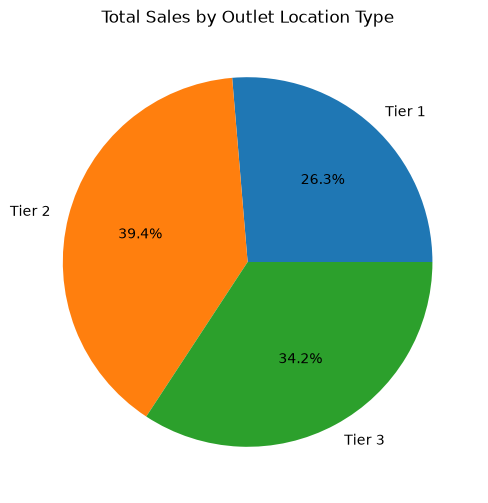

In [46]:
Sales_by_Outlet_Location = df.groupby('Outlet Location Type')['Sales'].sum().reset_index()

print(Sales_by_Outlet_Location)

## create pie chart
plt.figure(figsize=(8, 6))
plt.pie(
    Sales_by_Outlet_Location['Sales'],
    labels=Sales_by_Outlet_Location['Outlet Location Type'],
    autopct='%1.1f%%'
)
plt.title('Total Sales by Outlet Location Type')
plt.show()

##                                **THE END**